Introduction
In this mini-project, we will perform data analysis to devise a marketing strategy based on various aspects like area analysis, customer analysis, product category analysis, and sales and profit time series.



👩‍🏫 👩🏿‍🏫 What You’ll learn
How to load and preprocess a dataset.
Techniques for area analysis to identify key markets.
Methods for customer analysis to determine high-value customers.
Strategies for product category analysis to identify top-performing products.
How to analyze sales and profit trends over time.
Application of the Pareto Principle to prioritize key drivers of sales and profit.


Dataset
The US Superstore Dataset contains the following attributes:

Row ID: Unique ID for each row.
Order ID: Unique Order ID for each Customer.
Order Date: Order Date of the product.
Ship Date: Shipping Date of the Product.
Ship Mode: Shipping Mode specified by the Customer.
Customer ID: Unique ID to identify each Customer.
Customer Name: Name of the Customer.
Segment: The segment where the Customer belongs.
Country: Country of residence of the Customer.
City: City of residence of the Customer.
State: State of residence of the Customer.
Postal Code: Postal Code of every Customer.
Region: Region where the Customer belongs.
Product ID: Unique ID of the Product.
Category: Category of the product ordered.
Sub-Category: Sub-Category of the product ordered.
Product Name: Name of the Product.
Sales: Sales of the Product.
Quantity: Quantity of the Product.
Discount: Discount provided.
Profit: Profit/Loss incurred.



1. Which states have the most sales?
2. What is the difference between New York and California in terms of sales and profit? (Compare the total sales and profit between New York and California.)
3. Who is an outstanding customer in New York?
4. Are there any differences among states in profitability?
5. The Pareto Principle, also known as the 80/20 rule, is a concept derived from the work of Italian economist Vilfredo Pareto. It states that roughly 80% of the effects come from 20% of the causes. For instance, identifying the top 20% of products that generate 80% of sales or the top 20% of customers that contribute to 80% of profit can help in prioritizing efforts and resources. This focus can lead to improved efficiency and effectiveness in business strategies. Can we apply Pareto principle to customers and Profit ? (Determine if 20% of the customers contribute to 80% of the profit.)
6. What are the Top 20 cities by Sales ? What about the Top 20 cities by Profit ? Are there any difference among cities in profitability ? (Identify the top 20 cities based on total sales and total profit and analyze differences in profitability among these cities.)
7. Who are the top 20 customers by sales?
8. Plot the Cumulative curve in Sales by Customers. Can we apply Pareto principle to customers and Sales ?
9. Based on the analysis, make decisions on which states and cities to prioritize for marketing strategies.




First load the dataset in a notebook

In [ ]:
import pandas as pd
superstore_dataset = pd.read_excel("US_Superstore_data.xls")

display(superstore_dataset.head())
print(superstore_dataset.info())

Preprocess the data: inspecting the structure, fixing data types (especially dates), handling missing or duplicate rows, and standardizing text fields

In [26]:
#changed the spaces and the middle thing to an underscore
superstore_dataset.columns = (
    superstore_dataset.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace("-", "_")
)


In [ ]:
# Check missing values per column
print(superstore_dataset.isnull().sum())

#there is nothing missing

# Check and drop exact duplicate rows
print("Exact duplicates:", superstore_dataset.duplicated().sum())

#there are no duplicates

In [24]:
#change the dates to date-time
superstore_dataset["order_date"] = pd.to_datetime(superstore_dataset["order_date"])
superstore_dataset["ship_date"] = pd.to_datetime(superstore_dataset["ship_date"])


In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#1. Which states have the most sales?
# Group by State, sum Sales, and sort from highest to lowest
state_sales = (
    superstore_dataset.groupby("state", as_index=False)["sales"]
    .sum()
    .sort_values(by= "sales", ascending=False)
)

# Display the top 10 states
#display(state_sales.head(10))

# Get the top 10 states and reverse order so the #1 state appears at the top
top_10_states = state_sales.head(10).iloc[::-1]

# plt.figure(figsize=(12, 5))
bars = plt.barh(top_10_states["state"], top_10_states["sales"], color="green")

# Add title and axis labels
plt.title("Top 10 US States by Total Sales", fontsize=14, fontweight="bold", pad=10)
plt.xlabel("Total Sales ($)", fontsize=12)
plt.ylabel("State", fontsize=12)


plt.bar_label(bars, fmt=lambda x: f"${x:,.0f}", padding=5, fontsize=10)


# Expand x-axis limit slightly so labels fit cleanly inside the frame
plt.xlim(0, top_10_states["sales"].max() * 1.2)
plt.grid(linestyle="-", alpha=0.5)
# plt.tight_layout()
plt.show()


 



2. What is the difference between New York and California in terms of sales and profit? (Compare the total sales and profit between New York and California.)

In [62]:
# Filter for California and New York, then sum sales and profit
ny_ca = (
    superstore_dataset[superstore_dataset["state"].isin(["California", "New York"])]
    .groupby("state", as_index=False)[["sales", "profit"]]
    .sum()
)

display(ny_ca)

# Group with state as the row index
ny_ca_indexed = (
    superstore_dataset[superstore_dataset["state"].isin(["California", "New York"])]
    .groupby("state")[["sales", "profit"]]
    .sum()
)

# Use .loc directly with row and column names
ca_sales = ny_ca_indexed.loc["California", "sales"]
ny_sales = ny_ca_indexed.loc["New York", "sales"]

ca_profit = ny_ca_indexed.loc["California", "profit"]
ny_profit = ny_ca_indexed.loc["New York", "profit"]

sales_diff = ca_sales - ny_sales
profit_diff = ca_profit - ny_profit

print(f"Sales Difference (CA - NY):  ${sales_diff:,.2f}")
print(f"Profit Difference (CA - NY): ${profit_diff:,.2f}")


,state,sales,profit
0,California,457687.6315,76381.3871
1,New York,310876.2710,74038.5486


Sales Difference (CA - NY):  $146,811.36
Profit Difference (CA - NY): $2,342.84


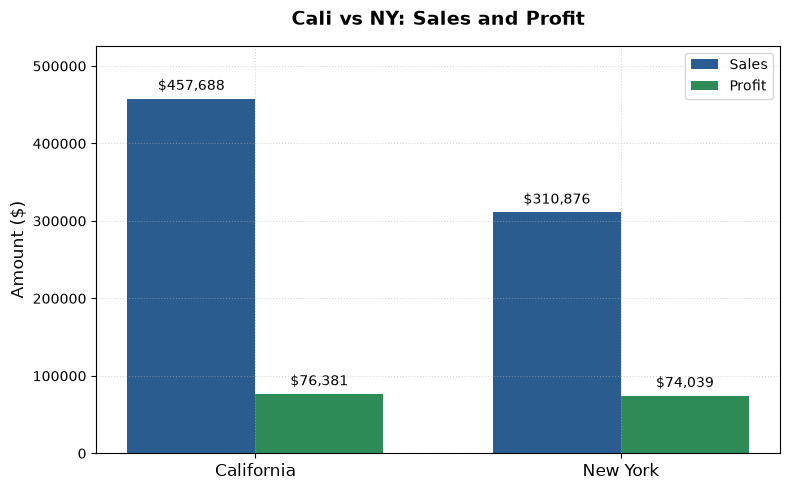

In [67]:
import matplotlib.pyplot as plt
import numpy as np

states = ["California", "New York"]
ny_ca_ordered = ny_ca.set_index("state").loc[states].reset_index()

x = np.arange(len(states))  # Positions for New York (0) and California (1)
width = 0.35                # Width of each bar

fig, ax = plt.subplots(figsize=(8, 5))

# Plot two bars side-by-side for each state
bars_sales = ax.bar(x - width/2, ny_ca_ordered["sales"], width, label="Sales", color="#2b5c8f")
bars_profit = ax.bar(x + width/2, ny_ca_ordered["profit"], width, label="Profit", color="#2e8b57")

# Add title, axis labels, and x-axis state ticks
ax.set_title("Cali vs NY: Sales and Profit", fontsize=14, fontweight="bold", pad=15)
ax.set_ylabel("Amount ($)", fontsize=12)
ax.set_xticks(x)
ax.set_xticklabels(states, fontsize=12)
ax.legend()

# Add formatted dollar labels above every bar
ax.bar_label(bars_sales, fmt=lambda v: f"${v:,.0f}", padding=4, fontsize=10)
ax.bar_label(bars_profit, fmt=lambda v: f"${v:,.0f}", padding=4, fontsize=10)

# Give extra space at the top so labels don't touch the border
ax.set_ylim(0, ny_ca_ordered["sales"].max() * 1.15)
ax.grid(axis="both", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.show()


3. Who is an outstanding customer in New York?

In [ ]:
# Filter for the State of New York (use df['City'] == 'New York City' if filtering by city)
new_york_customers = superstore_dataset[superstore_dataset["state"] == "New York"].copy()

# Group by Customer_ID and Name, then aggregate Sales, Profit, and Order Count
top_ny_customers = (
    new_york_customers.groupby(["customer_name","customer_id"], as_index=False)
    .agg(
        Total_Sales=('sales', 'sum'),
        Total_Profit=('profit', 'sum'),
        Order_Count=('order_id', 'nunique'),
        Total_Quantity=('quantity', 'sum'),
    )
)

metrics = ['Total_Sales', 'Total_Profit', 'Order_Count', 'Total_Quantity']

for column in metrics:
  top_5 = top_ny_customers.sort_values(by=column, ascending=False).head(5)

  print(f"\nTop 5 #1 NY Customers by category: {column}")
  
  print(
      top_5[["customer_name", column]].to_string(index=False, header=False)
  )

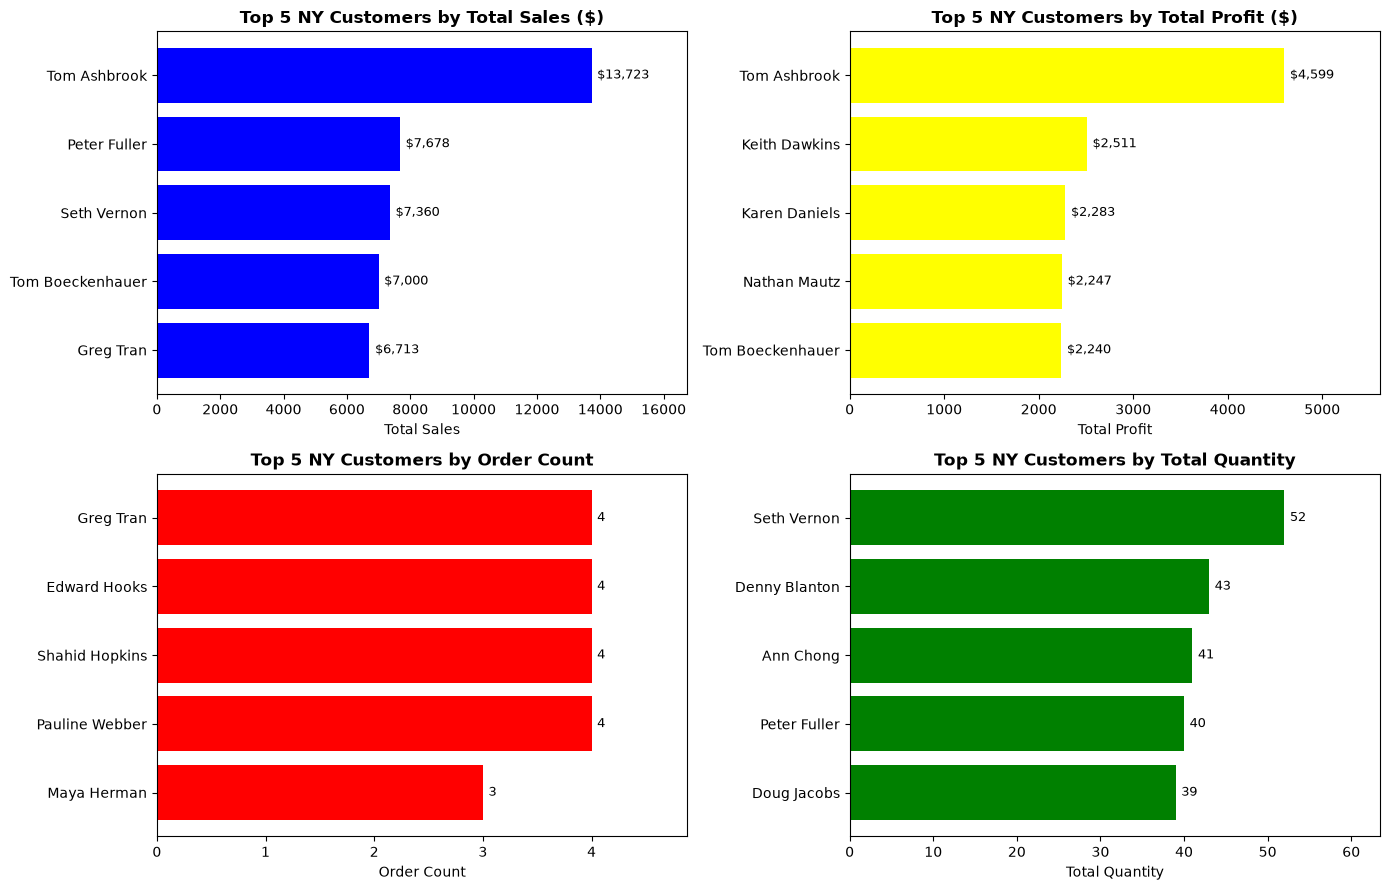

In [119]:
import matplotlib.pyplot as plt

titles = [
    "Top 5 NY Customers by Total Sales ($)",
    "Top 5 NY Customers by Total Profit ($)",
    "Top 5 NY Customers by Order Count",
    "Top 5 NY Customers by Total Quantity",
]
colors = ["blue", "yellow", "red", "green"]

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()  

# Pair each chart box directly with its metric, title, and color
for axis, column, title, color in zip(axes, metrics, titles, colors):
  # Sort descending to grab top 5, then ascending so #1 sits at the top of the chart
  top_5 = top_ny_customers.sort_values(by=column, ascending=False).head(5)
  top_5 = top_5.sort_values(by=column, ascending=True)

  bars = axis.barh(top_5["customer_name"], top_5[column], color=color)
  axis.set_title(title, fontsize=12, fontweight="bold")
  axis.set_xlabel(column.replace("_", " "))
  
  labels = [
        f"${v:,.0f}" if "Sales" in column or "Profit" in column else f"{int(v):,}"
        for v in top_5[column]]
  
  axis.bar_label(bars, labels=labels, padding=4, fontsize=9)
  axis.margins(x=0.22)
# axis.set_xlim(0, top_5[column].max() * 2)


plt.tight_layout()
plt.show()

4. Are there any differences among states in profitability?

In [130]:
state_performance = (
    superstore_dataset.groupby("state", as_index=False)
    .agg(
        Total_State_Sales=("sales", "sum"),
        Total_State_Profit=("profit", "sum"),
        Avg_State_Discount=("discount", "mean"),
    )
    .sort_values(by="Total_State_Profit", ascending=False)
)

print("Top Five Most Profitable States")
print(state_performance.head(5).rename(columns={"state": "State"}).to_string(index=False))

print("\nBottom 5 Loss-Making States")
print(state_performance.tail(5).rename(columns={"state":"State"}).to_string(index=False))

# 2. Plot Top 10 vs. Bottom 10 States side by side
top_10 = state_performance.head(10).sort_values("Total_State_Profit", ascending=True)
bottom_10 = state_performance.tail(10).sort_values("Total_State_Profit", ascending=False)


Top Five Most Profitable States
     State  Total_State_Sales  Total_State_Profit  Avg_State_Discount
California        457687.6315          76381.3871            0.072764
  New York        310876.2710          74038.5486            0.055319
Washington        138641.2700          33402.6517            0.064032
  Michigan         76269.6140          24463.1876            0.007059
  Virginia         70636.7200          18597.9504            0.000000

Bottom 5 Loss-Making States
         State  Total_State_Sales  Total_State_Profit  Avg_State_Discount
North Carolina         55603.1640          -7490.9122            0.283534
      Illinois         80166.1010         -12607.8870            0.390041
  Pennsylvania        116511.9140         -15559.9603            0.328620
          Ohio         78258.1360         -16971.3766            0.324947
         Texas        170188.0458         -25729.3563            0.370193


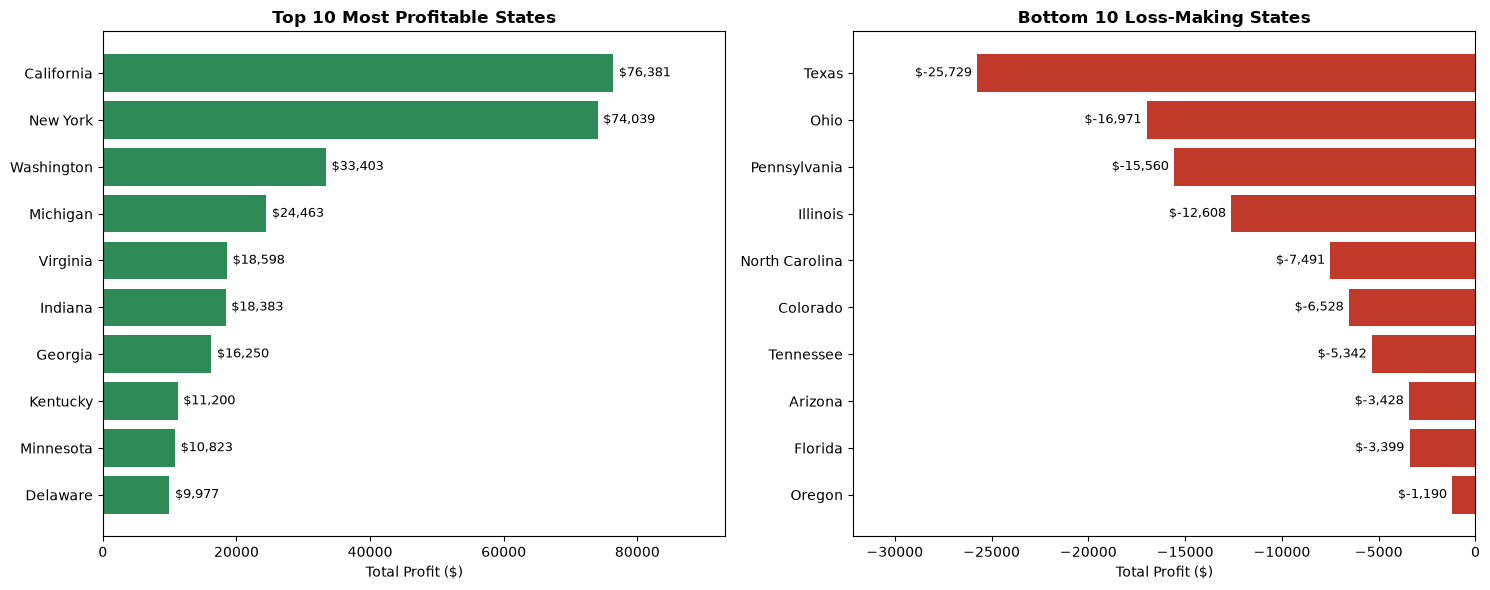

In [133]:
top_10 = state_performance.head(10).sort_values("Total_State_Profit", ascending=True)
bottom_10 = state_performance.tail(10).sort_values("Total_State_Profit", ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

bars1 = ax1.barh(top_10["state"], top_10["Total_State_Profit"], color="#2e8b57")
ax1.set_title("Top 10 Most Profitable States", fontsize=12, fontweight="bold")
ax1.set_xlabel("Total Profit ($)")
ax1.bar_label(
    bars1,
    labels=[f"${v:,.0f}" for v in top_10["Total_State_Profit"]],
    padding=4,
    fontsize=9,
)
ax1.margins(x=0.22)

# Bottom 10 Loss-Making States
bars2 = ax2.barh(
    bottom_10["state"], bottom_10["Total_State_Profit"], color="#c0392b"
)
ax2.set_title("Bottom 10 Loss-Making States", fontsize=12, fontweight="bold")
ax2.set_xlabel("Total Profit ($)")
ax2.bar_label(
    bars2,
    labels=[f"${v:,.0f}" for v in bottom_10["Total_State_Profit"]],
    padding=4,
    fontsize=9,
)
ax2.margins(x=0.25)

plt.tight_layout()
plt.show()

5. The Pareto Principle, also known as the 80/20 rule, is a concept derived from the work of Italian economist Vilfredo Pareto. It states that roughly 80% of the effects come from 20% of the causes. For instance, identifying the top 20% of products that generate 80% of sales or the top 20% of customers that contribute to 80% of profit can help in prioritizing efforts and resources. This focus can lead to improved efficiency and effectiveness in business strategies. Can we apply Pareto principle to customers and Profit ? 
(Determine if the top(!) 20% of the customers contribute to 80% of the profit.)

In [ ]:
customer_profit = (
    superstore_dataset.groupby(["customer_id", "customer_name"], as_index=False)
    .agg(Total_Customer_Profit=("profit", "sum"))
    .sort_values(by="Total_Customer_Profit", ascending=False)
    .reset_index(drop=True)
)

total_customers = len(customer_profit)
total_customer_profit = customer_profit["Total_Customer_Profit"].sum()

customer_profit["Customer_Cumulative_Percentage"] = (customer_profit.index + 1) / total_customers * 100

customer_profit["Profit_Cumulative_Percentage"] = (customer_profit["Total_Customer_Profit"].cumsum() / total_customer_profit * 100)


 
top_20_cutoff = int(total_customers * 0.20)
profit_share_at_20 = customer_profit.loc[top_20_cutoff - 1, "Profit_Cumulative_Percentage"]
cust_needed_for_80 = customer_profit[customer_profit["Profit_Cumulative_Percentage"] >= 80].index[0] + 1
cust_pct_for_80 = cust_needed_for_80 / total_customers * 100

print(f"Total Customers: {total_customers}")
print(f"Top 20% ({top_20_cutoff} customers) generate: {profit_share_at_20:.2f}% of total profit")
print(f"80% of total profit comes from just {cust_pct_for_80:.2f}% ({cust_needed_for_80} customers)")

Total Customers: 793
Top 20% (158 customers) generate: 81.43% of total profit
80% of total profit comes from just 19.29% (153 customers)


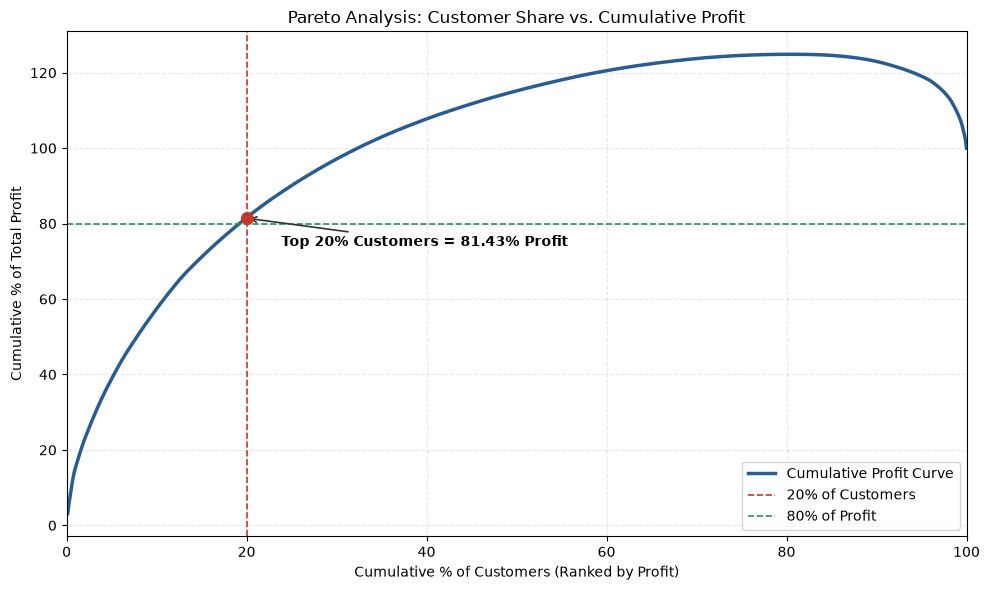

In [177]:
fig, ax = plt.subplots(figsize=(10, 6))

# 1. Plot the main cumulative profit curve
ax.plot(
    customer_profit["Customer_Cumulative_Percentage"],
    customer_profit["Profit_Cumulative_Percentage"],
    color="#2b5c8f",
    linewidth=2.5,
    label="Cumulative Profit Curve",
)

ax.axvline(
    x=20,
    color="#c0392b",
    linestyle="--",
    linewidth=1.2,
    label="20% of Customers",
)

ax.axhline(
    y=80, color="#2e8b57", linestyle="--", linewidth=1.2, label="80% of Profit")

ax.scatter(x=[20], y=[profit_share_at_20], color="#c0392b", s=72, zorder=10)

ax.annotate(
    text=f"Top 20% Customers = {profit_share_at_20:.2f}% Profit",
    xy=(20, profit_share_at_20),
    xytext=(25, -20),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#333333", "linewidth": 1.2},
    fontsize=10,
    fontweight="bold",
)

# 4. Configure titles, axis limits, spines, and legend
ax.set(
    title="Pareto Analysis: Customer Share vs. Cumulative Profit",
    xlabel="Cumulative % of Customers (Ranked by Profit)",
    ylabel="Cumulative % of Total Profit",
    xlim=(0, 100),
)
# ax.spines[["top", "right"]].set_visible(False)
ax.grid(visible=True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


6. What are the Top 20 cities by Sales ? 
What about the Top 20 cities by Profit ? 
Are there any difference among cities in profitability ? (Identify the top 20 cities based on total sales and total profit and analyze differences in profitability among these cities.)

In [ ]:
# 1. Aggregate metrics and create calculated columns in one chained pipeline
city_perf = (
    superstore_dataset.groupby(["city", "state"], as_index=False)
    .agg(
        Total_city_Sales=("sales", "sum"),
        Total_city_Profit=("profit", "sum"),
        Avg_city_Discount=("discount", "mean"),
    )
    .assign(
        Profit_Margin_Pct=lambda d: (d["Total_city_Profit"] / d["Total_city_Sales"] * 100).round(2),
        City_State=lambda d: d["city"] + ", " + d["state"],
    )
)

# 2. Grab Top 20 by Sales and Profit directly with .nlargest()
top_20_sales = city_perf.nlargest(20, "Total_city_Sales")
top_20_profit = city_perf.nlargest(20, "Total_city_Profit")


#REVIEW FROM HERE ON IN
# 3. Print both tables using a single loop
for label, df_top in [("Sales", top_20_sales), ("Profit", top_20_profit)]:
    print(f"\n--- Top 20 Cities by {label} ---")
    cols = ["City_State", "Total_city_Sales", "Total_city_Profit", "Profit_Margin_Pct"]
    print(df_top[cols].to_string(index=False))

# 4. Plot both side-by-side charts using a single loop (eliminates duplicate ax1/ax2 code)
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

configs = [
    (axes[0], top_20_sales, "Total_city_Sales", "Top 20 Cities by Sales (Green = Profitable, Red = Net Loss)"),
    (axes[1], top_20_profit, "Total_city_Profit", "Top 20 Cities by Total Profit"),
]

for ax, df_top, metric, title in configs:
    plot_df = df_top.sort_values(by=metric, ascending=True)
    colors = (
        ["#2e8b57" if p >= 0 else "#c0392b" for p in plot_df["Total_Profit"]]
        if metric == "Total_Sales"
        else "#2b5c8f"
    )

    bars = ax.barh(plot_df["City_State"], plot_df[metric], color=colors)
    ax.set(title=title, xlabel=f"{metric.replace('_', ' ')} ($)")
    ax.bar_label(bars, labels=[f"${v:,.0f}" for v in plot_df[metric]], padding=4, fontsize=8.5)
    ax.spines[["top", "right"]].set_visible(False)
    ax.margins(x=0.22)

plt.tight_layout()
plt.show()


7. Who are the top 20 customers by sales?

In [187]:
top_20_customers = (
    superstore_dataset.groupby(["customer_name","customer_id"], as_index=False)
    .agg(total_customer_sales=("sales", "sum"))
    .sort_values(by="total_customer_sales",ascending=False)
    .head(20)
    .reset_index(drop=True)
)

top_20_customers.insert(0, "Rank", top_20_customers.index + 1)

print(top_20_customers.to_string(index=False))



 Rank      customer_name customer_id  total_customer_sales
    1        Sean Miller    SM-20320             25043.050
    2       Tamara Chand    TC-20980             19052.218
    3       Raymond Buch    RB-19360             15117.339
    4       Tom Ashbrook    TA-21385             14595.620
    5      Adrian Barton    AB-10105             14473.571
    6       Ken Lonsdale    KL-16645             14175.229
    7       Sanjit Chand    SC-20095             14142.334
    8       Hunter Lopez    HL-15040             12873.298
    9       Sanjit Engle    SE-20110             12209.438
   10 Christopher Conant    CC-12370             12129.072
   11       Todd Sumrall    TS-21370             11891.751
   12          Greg Tran    GT-14710             11820.120
   13       Becky Martin    BM-11140             11789.630
   14        Seth Vernon    SV-20365             11470.950
   15    Caroline Jumper    CJ-12010             11164.974
   16        Clay Ludtke    CL-12565             10880.5

8. Plot the Cumulative curve in Sales by Customers. Can we apply Pareto principle to customers and Sales?

Top 20% (158 customers) generate: 47.96% of total sales
80% of total sales requires: 49.94% (396 customers)
=== Pareto Check: Sales ===
IT DID NOT WORK: The top 20% of customers generate only 48.0% of total sales.
Why: Every customer contributes positive sales (no negative values), spreading revenue more evenly so it takes 49.9% of customers to reach 80%.



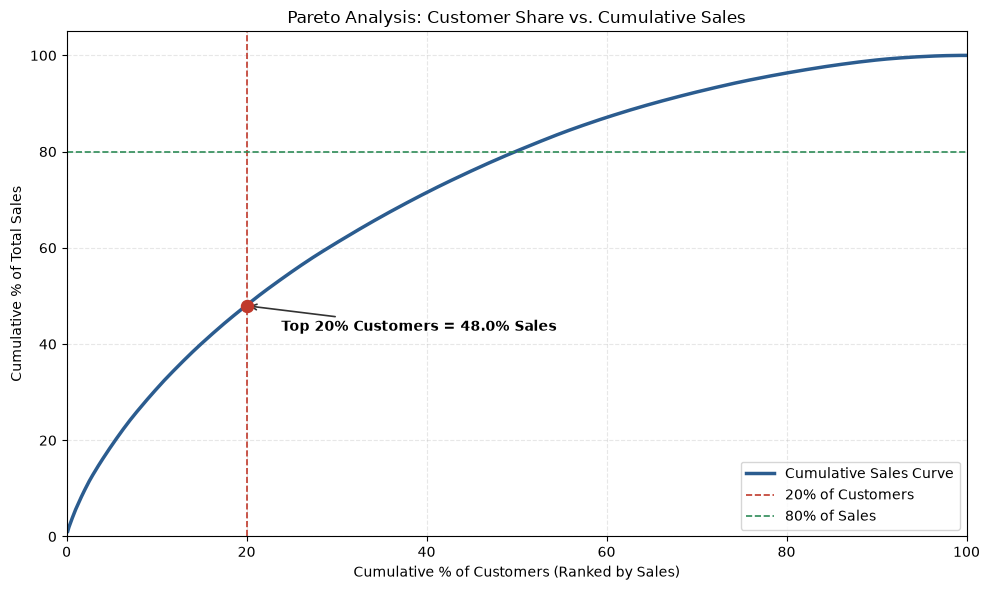

In [ ]:
cust_sales = (
    superstore_dataset.groupby(["customer_id", "customer_name"], as_index=False)
    .agg(Total_Sales=("sales", "sum"))
    .sort_values(by="Total_Sales", ascending=False)
    .reset_index(drop=True)
)

total_customers = len(cust_sales)
total_sales = cust_sales["Total_Sales"].sum()

cust_sales["Cust_Cum_Pct"] = (cust_sales.index + 1) / total_customers * 100
cust_sales["Sales_Cum_Pct"] = cust_sales["Total_Sales"].cumsum() / total_sales * 100


top_20_cutoff = int(total_customers * 0.20)
sales_share_at_20 = cust_sales.loc[top_20_cutoff - 1, "Sales_Cum_Pct"]
cust_needed_for_80 = cust_sales[cust_sales["Sales_Cum_Pct"] >= 80].index[0] + 1
cust_pct_for_80 = cust_needed_for_80 / total_customers * 100

print(f"Top 20% ({top_20_cutoff} customers) generate: {sales_share_at_20:.2f}% of total sales")
print(f"80% of total sales requires: {cust_pct_for_80:.2f}% ({cust_needed_for_80} customers)")


#gotta go over the next 20 lines or so
# Test the 80/20 Pareto Principle for both Profit and Sales in a single loop
metrics_to_test = [
    ("sales", "Sales"),
]

for col, label in metrics_to_test:
  # 1. Aggregate and sort highest to lowest
  df_pareto = (
      superstore_dataset.groupby(
          ["customer_id", "customer_name"], as_index=False
      )
      .agg(Total=(col, "sum"))
      .sort_values(by="Total", ascending=False)
      .reset_index(drop=True)
  )

  # 2. Calculate cumulative percentages
  total_customers = len(df_pareto)
  df_pareto["Cum_Pct"] = (
      df_pareto["Total"].cumsum() / df_pareto["Total"].sum() * 100
  )

  # 3. Measure share at the 20% customer mark and customers needed for 80%
  top_20_cutoff = int(total_customers * 0.20)
  share_at_20 = float(df_pareto.loc[top_20_cutoff - 1, "Cum_Pct"])
  cust_pct_for_80 = (
      (df_pareto[df_pareto["Cum_Pct"] >= 80].index[0] + 1) / total_customers * 100
  )

  # 4. Evaluate whether the 80/20 rule holds
  print(f"=== Pareto Check: {label} ===")
  if share_at_20 >= 80:
    print(
        f"IT WORKED: The top 20% of customers generate {share_at_20:.1f}% of"
        f" total {label.lower()}."
    )
    print(
        f"Why: Roughly 20% of customers have negative net {label.lower()} due to"
        " heavy discounting, concentrating overall earnings in the top"
        f" {cust_pct_for_80:.1f}% of buyers.\n"
    )
  else:
    print(
        f"IT DID NOT WORK: The top 20% of customers generate only"
        f" {share_at_20:.1f}% of total {label.lower()}."
    )
    print(
        f"Why: Every customer contributes positive {label.lower()} (no"
        " negative values), spreading revenue more evenly so it takes"
        f" {cust_pct_for_80:.1f}% of customers to reach 80%.\n"
    )


# 4. Plot the Cumulative Sales Curve
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(
    cust_sales["Cust_Cum_Pct"],
    cust_sales["Sales_Cum_Pct"],
    color="#2b5c8f",
    linewidth=2.5,
    label="Cumulative Sales Curve",
)

# Reference lines for 20% customers and 80% sales
ax.axvline(x=20, color="#c0392b", linestyle="--", linewidth=1.2, label="20% of Customers")
ax.axhline(y=80, color="#2e8b57", linestyle="--", linewidth=1.2, label="80% of Sales")

# Highlight the actual sales share at the 20% customer mark
ax.scatter(x=[20], y=[sales_share_at_20], color="#c0392b", s=75, zorder=5)
ax.annotate(
    text=f"Top 20% Customers = {sales_share_at_20:.1f}% Sales",
    xy=(20, sales_share_at_20),
    xytext=(25, -18),
    textcoords="offset points",
    arrowprops={"arrowstyle": "->", "color": "#333333", "linewidth": 1.2},
    fontsize=10,
    fontweight="bold",
)

ax.set(
    title="Pareto Analysis: Customer Share vs. Cumulative Sales",
    xlabel="Cumulative % of Customers (Ranked by Sales)",
    ylabel="Cumulative % of Total Sales",
    xlim=(0, 100),
    ylim=(0, 105),
)

ax.grid(visible=True, linestyle="--", alpha=0.3)
ax.legend(loc="lower right")

plt.tight_layout()
plt.show()


9. Based on the analysis, make decisions on which states and cities to prioritize for marketing strategies.
You want to target the states and cities which have the most profit margin, not necessarily the most sales (because sometimes those sales come with a loss) and not the places who sold the most items (same reasoning)

In [204]:
# 1. Rank States by Profit Margin (minimum 5 orders to avoid tiny outliers)
state_margin = (
    superstore_dataset.groupby("state", as_index=False)
    .agg(
        Total_Sales=("sales", "sum"),
        Total_Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
    )
    .query("Orders >= 5")
    .assign(
        Profit_Margin_Pct=lambda d: (d["Total_Profit"] / d["Total_Sales"] * 100).round(2)
    )
    .sort_values(by="Profit_Margin_Pct", ascending=False)
)

print("--- Top 3 States by Profit Margin ---")
print(
    state_margin[["state", "Orders", "Profit_Margin_Pct"]]
    .head(3)
    .rename(columns={"state": "State"})
    .to_string(index=False)
)

print("\n--- Bottom 3 States by Profit Margin ---")
print(
    state_margin[["state", "Orders", "Profit_Margin_Pct"]]
    .tail(3)
    .rename(columns={"state": "State"})
    .to_string(index=False)
)

# 2. Rank Cities by Profit Margin (minimum 5 orders)
city_margin = (
    superstore_dataset.groupby(["city", "state"], as_index=False)
    .agg(
        Total_Sales=("sales", "sum"),
        Total_Profit=("profit", "sum"),
        Orders=("order_id", "nunique"),
    )
    .query("Orders >= 5")
    .assign(
        City_State=lambda d: d["city"] + ", " + d["state"],
        Profit_Margin_Pct=lambda d: (
            d["Total_Profit"] / d["Total_Sales"] * 100
        ).round(2),
    )
    .sort_values(by="Profit_Margin_Pct", ascending=False)
)

print("\n--- Top 3 Cities by Profit Margin ---")
print(
    city_margin[["City_State", "Orders", "Profit_Margin_Pct"]]
    .head(3)
    .rename(columns={"City_State": "City, State"})
    .to_string(index=False)
)

print("\n--- Bottom 3 Cities by Profit Margin ---")
print(
    city_margin[["City_State", "Orders", "Profit_Margin_Pct"]]
    .rename(columns={"City_State": "City, State"})
    .tail(3)
    .to_string(index=False)
)

top_3_cities = ", ".join(city_margin["City_State"].head(3))
print(f"\nTop Performers Strategy: Scale successful campaigns and increase ad spend in {top_3_cities} to maximize returns from our highest-margin markets.")

# --- Bottom 3 Cities ---
print("\n--- Bottom 3 Cities by Profit Margin ---")
print(
    city_margin[["City_State", "Orders", "Profit_Margin_Pct"]]
    .tail(3)
    .to_string(index=False, header=["City, State", "Orders", "Profit_Margin_Pct"])
)

bottom_3_cities = ", ".join(city_margin["City_State"].tail(3))
print(f"\nUnderperformers Strategy: Review discount structures and adjust local marketing budgets in {bottom_3_cities} to improve low profit margins.")



--- Top 3 States by Profit Margin ---
    State  Orders  Profit_Margin_Pct
 Delaware      44              36.35
Minnesota      44              36.24
  Indiana      73              34.33

--- Bottom 3 States by Profit Margin ---
    State  Orders  Profit_Margin_Pct
Tennessee      91             -17.42
 Colorado      79             -20.33
     Ohio     236             -21.69

--- Top 3 Cities by Profit Margin ---
           City, State  Orders  Profit_Margin_Pct
    Lafayette, Indiana       7              45.73
Fayetteville, Arkansas       8              45.21
Grand Rapids, Michigan       6              44.46

--- Bottom 3 Cities by Profit Margin ---
         City, State  Orders  Profit_Margin_Pct
    Skokie, Illinois       5             -60.98
Louisville, Colorado      12             -67.18
     Lancaster, Ohio      15             -87.16

Top Performers Strategy: Scale successful campaigns and increase ad spend in Lafayette, Indiana, Fayetteville, Arkansas, Grand Rapids, Michigan to max